# Hepatitis C Screening from a Liver Panel

**Team A-9 · BCP308 · Research prototype**

Does a model trained on ten laboratory measurements distinguish the three disease categories from blood donors in the UCI HCV dataset? A secondary experiment retains all five source categories. These labels and scores are for retrospective education only. They do not diagnose active HCV, establish disease stage, or determine donor eligibility. See [WHO's hepatitis C testing guidance](https://www.who.int/news-room/fact-sheets/detail/hepatitis-c).

Run the cells in order in Google Colab using a CPU runtime. The notebook downloads the original [UCI HCV Data archive](https://archive.ics.uci.edu/dataset/571/hcv%2Bdata) (Lichtinghagen, Klawonn & Hoffmann, 2020, [DOI](https://doi.org/10.24432/C5D612), CC BY 4.0).

In [1]:
import hashlib
import io
import os
import platform
from pathlib import Path
from time import perf_counter
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, PrecisionRecallDisplay, average_precision_score,
    classification_report, confusion_matrix, f1_score, precision_recall_curve,
    precision_score, recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

started = perf_counter()
SEED = 42
TARGET_RECALL = 0.80
URL = 'https://archive.ics.uci.edu/static/public/571/hcv+data.zip'
FEATURES = ['ALB', 'ALP', 'ALT', 'AST', 'BIL', 'CHE', 'CHOL', 'CREA', 'GGT', 'PROT']
CLASSES = ['Blood donor', 'Suspect donor', 'Hepatitis', 'Fibrosis', 'Cirrhosis']
LABELS = dict(zip(
    ['0=Blood Donor', '0s=suspect Blood Donor', '1=Hepatitis', '2=Fibrosis', '3=Cirrhosis'],
    CLASSES,
))
local_zip = os.environ.get('A9_HCV_ZIP')
if local_zip:
    archive = Path(local_zip).read_bytes()
else:
    with urlopen(URL, timeout=30) as response:
        archive = response.read()
with ZipFile(io.BytesIO(archive)) as z:
    with z.open('hcvdat0.csv') as f:
        raw = pd.read_csv(f, index_col=0)
y = raw['Category'].map(LABELS)
X = raw[FEATURES].apply(pd.to_numeric, errors='raise')
assert raw.index.is_unique and len(raw) == 615 and y.notna().all()
assert y.value_counts().reindex(CLASSES).tolist() == [533, 7, 24, 21, 30]
duplicates = X.duplicated(keep=False)
if duplicates.any():
    labels_per_panel = X.loc[duplicates].assign(label=y.loc[duplicates]).groupby(
        FEATURES, dropna=False,
    )['label'].nunique()
    assert labels_per_panel.eq(1).all(), 'Investigate conflicting labels on identical panels.'
keep = ~X.duplicated()
print(f'Python {platform.python_version()} | sklearn {sklearn.__version__} | '
      f'pandas {pd.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__}')
print('Original archive SHA256:', hashlib.sha256(archive).hexdigest())
display(y.value_counts().reindex(CLASSES).rename('Records').to_frame())
print(f'Removed {int((~keep).sum())} repeat panels with the same label before splitting.')
X, y = X.loc[keep], y.loc[keep]
display(X.isna().sum().rename('Missing values').to_frame())

Python 3.14.7 | sklearn 1.8.0 | pandas 3.1.1 | numpy 2.5.5 | matplotlib 3.11.2
Original archive SHA256: 0fafa2c4ae94db98b95f35cd41e9f4cedbd1e105282ab0cd7b5ed3effe5a05d8


,Records
Category,
Blood donor,533
Suspect donor,7
Hepatitis,24
Fibrosis,21
Cirrhosis,30


Removed 7 repeat panels with the same label before splitting.


,Missing values
ALB,1
ALP,18
ALT,1
AST,0
BIL,0
CHE,0
CHOL,10
CREA,0
GGT,0
PROT,1


## Split and model design

Remove exact repeats on the ten model inputs with the same label before splitting, so identical panels cannot appear in both training and testing. Reserve a stratified 20% test set for both experiments. The binary task excludes suspect donors because their label is ambiguous. Its positive label denotes membership in the three named disease groups, without inferring RNA status. The five-class task includes all labels. Row numbers, age and sex are excluded. All imputation and scaling are fitted inside each training fold. We compare a majority baseline, regularized logistic regression and a random forest. Class weighting gives rare classes more influence during fitting.

In [2]:
train_ids, test_ids = train_test_split(y.index, test_size=0.20, stratify=y, random_state=SEED)
assert not set(train_ids).intersection(test_ids)
assert set(train_ids).union(test_ids) == set(X.index)
assert not X.duplicated().any()
binary_ids = y.index[y != 'Suspect donor']
train_binary = pd.Index(train_ids).intersection(binary_ids)
test_binary = pd.Index(test_ids).intersection(binary_ids)
y_bin = y.loc[binary_ids].ne('Blood donor').astype(int)
display(pd.DataFrame({'train': y.loc[train_ids].value_counts(),
                      'test': y.loc[test_ids].value_counts()}).reindex(CLASSES))
assert y.loc[train_ids].value_counts().min() >= 5
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
baseline = make_pipeline(SimpleImputer(strategy='median'), DummyClassifier(strategy='most_frequent'))
candidates = {
    'Logistic regression': make_pipeline(
        SimpleImputer(strategy='median'), StandardScaler(),
        LogisticRegression(class_weight='balanced', max_iter=2000, random_state=SEED),
    ),
    'Random forest': make_pipeline(
        SimpleImputer(strategy='median'),
        RandomForestClassifier(
            n_estimators=160, min_samples_leaf=2, class_weight='balanced',
            random_state=SEED, n_jobs=1,
        ),
    ),
}

,train,test
Category,,
Blood donor,420,106
Suspect donor,6,1
Hepatitis,19,5
Fibrosis,17,4
Cirrhosis,24,6


## Binary evaluation

Select a model by average precision on out-of-fold training predictions. On those same predictions, choose the threshold with the best precision among thresholds reaching 80% recall. Break precision ties by higher recall, then higher threshold. The 80% goal is a study target, not a clinical requirement. Freeze both decisions before scoring the test set. Keep the majority baseline at its default operating point.

Chosen by training validation: Random forest at threshold 0.4891


,precision,recall,average_precision,tn,fp,fn,tp,threshold
Logistic regression,0.8421,0.8,0.8529,411,9,12,48,0.7007
Random forest,0.9231,0.8,0.9478,416,4,12,48,0.4891


,precision,recall,average_precision,tn,fp,fn,tp
Majority baseline,0.0,0.0000,0.124,106,0,15,0
Random forest,1.0,0.9333,1.000,106,0,1,14


Held-out target reached: True


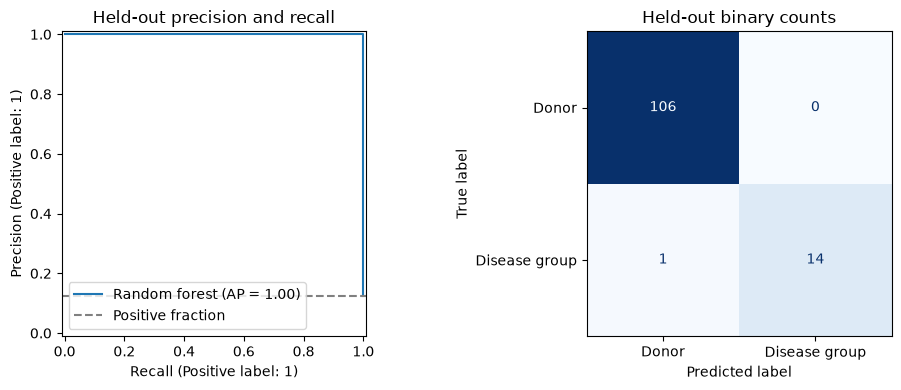

In [3]:
def choose_threshold(truth, scores, minimum_recall):
    precision, recall, thresholds = precision_recall_curve(truth, scores)
    eligible = np.flatnonzero(recall[:-1] >= minimum_recall)
    winner = max(eligible, key=lambda i: (precision[i], recall[i], thresholds[i]))
    return float(thresholds[winner])

def binary_metrics(truth, pred, scores):
    tn, fp, fn, tp = confusion_matrix(truth, pred, labels=[0, 1]).ravel()
    return dict(
        precision=precision_score(truth, pred, zero_division=0),
        recall=recall_score(truth, pred),
        average_precision=average_precision_score(truth, scores),
        tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp),
    )

validation = {}
cutoffs = {}
for name, estimator in candidates.items():
    scores = cross_val_predict(
        estimator, X.loc[train_binary], y_bin.loc[train_binary],
        cv=cv, method='predict_proba',
    )[:, 1]
    cutoffs[name] = choose_threshold(y_bin.loc[train_binary], scores, TARGET_RECALL)
    validation[name] = binary_metrics(
        y_bin.loc[train_binary], scores >= cutoffs[name], scores,
    ) | {'threshold': cutoffs[name]}
    assert validation[name]['recall'] >= TARGET_RECALL
binary_choice = max(validation, key=lambda name: validation[name]['average_precision'])
threshold = cutoffs[binary_choice]
print(f'Chosen by training validation: {binary_choice} at threshold {threshold:.4f}')
display(pd.DataFrame.from_dict(validation, orient='index').round(4))

test_truth = y_bin.loc[test_binary]
binary_model = clone(candidates[binary_choice]).fit(X.loc[train_binary], y_bin.loc[train_binary])
test_scores = binary_model.predict_proba(X.loc[test_binary])[:, 1]
test_flags = test_scores >= threshold
dummy_binary = clone(baseline).fit(X.loc[train_binary], y_bin.loc[train_binary])
dummy_scores = dummy_binary.predict_proba(X.loc[test_binary])[:, 1]
binary_result = binary_metrics(test_truth, test_flags, test_scores)
display(pd.DataFrame.from_dict({
    'Majority baseline': binary_metrics(test_truth, dummy_scores >= 0.5, dummy_scores),
    binary_choice: binary_result,
}, orient='index').round(4))
print(f"Held-out target reached: {binary_result['recall'] >= TARGET_RECALL}")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
PrecisionRecallDisplay.from_predictions(test_truth, test_scores, ax=axes[0], name=binary_choice)
axes[0].axhline(test_truth.mean(), color='gray', linestyle='--', label='Positive fraction')
axes[0].legend(loc='lower left')
ConfusionMatrixDisplay.from_predictions(
    test_truth, test_flags, labels=[0, 1], display_labels=['Donor', 'Disease group'],
    colorbar=False, ax=axes[1], cmap='Blues',
)
axes[0].set_title('Held-out precision and recall')
axes[1].set_title('Held-out binary counts')
fig.tight_layout()
plt.show()

## Five-class evaluation

Select by out-of-fold macro F1 so that common donors cannot dominate model selection. The five classes are nominal. With very few suspect donors, one prediction can greatly change that class's recall.

,Training validation macro F1
Majority baseline,0.1854
Logistic regression,0.6133
Random forest,0.5920


Selected Logistic regression. Test macro F1: 0.5400
Majority test macro F1: 0.1860


,precision,recall,f1-score,support
Blood donor,1.000,0.972,0.986,106.0
Suspect donor,0.500,1.000,0.667,1.0
Hepatitis,0.286,0.400,0.333,5.0
Fibrosis,0.000,0.000,0.000,4.0
Cirrhosis,0.625,0.833,0.714,6.0
macro avg,0.482,0.641,0.540,122.0


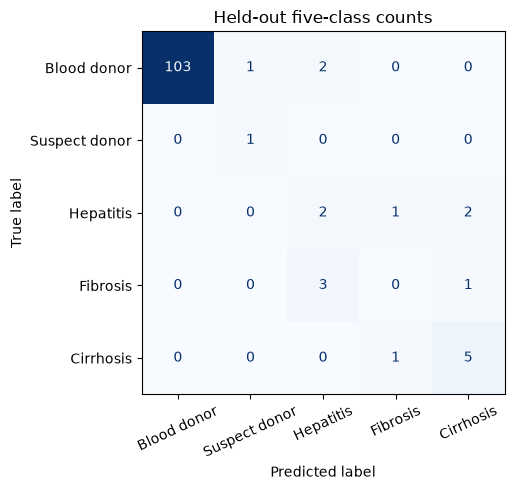

In [4]:
multi_validation = {}
for name, estimator in {'Majority baseline': baseline, **candidates}.items():
    predictions = cross_val_predict(estimator, X.loc[train_ids], y.loc[train_ids], cv=cv)
    multi_validation[name] = f1_score(
        y.loc[train_ids], predictions, labels=CLASSES, average='macro', zero_division=0,
    )
multi_choice = max(candidates, key=multi_validation.get)
display(pd.Series(multi_validation, name='Training validation macro F1').round(4).to_frame())
multi_model = clone(candidates[multi_choice]).fit(X.loc[train_ids], y.loc[train_ids])
multi_pred = multi_model.predict(X.loc[test_ids])
multi_baseline_pred = clone(baseline).fit(X.loc[train_ids], y.loc[train_ids]).predict(X.loc[test_ids])
report = classification_report(
    y.loc[test_ids], multi_pred, labels=CLASSES, output_dict=True, zero_division=0,
)
print(f"Selected {multi_choice}. Test macro F1: {report['macro avg']['f1-score']:.4f}")
print(f"Majority test macro F1: {f1_score(y.loc[test_ids], multi_baseline_pred, labels=CLASSES, average='macro', zero_division=0):.4f}")
display(pd.DataFrame(report).T.loc[CLASSES + ['macro avg']].round(3))
fig, ax = plt.subplots(figsize=(7.5, 5))
ConfusionMatrixDisplay.from_predictions(
    y.loc[test_ids], multi_pred, labels=CLASSES, xticks_rotation=25, colorbar=False,
    ax=ax, cmap='Blues',
)
ax.set_title('Held-out five-class counts')
fig.tight_layout()
plt.show()

## Demonstration and limitations

Show one held-out example for each binary outcome present. The score is a model ranking signal and is not a calibrated chance of infection. One check masks ALT for a held-out example to verify that the fitted pipelines can impute a missing input; it does not validate performance on incomplete panels. Explain a missed case or false flag if the test split contains one.

The held-out data come from the same public dataset as training. Donors and clinical patients differ in how they enter that dataset, so the model may learn characteristics of those groups that will not transfer to a local facility or to earlier infection. Clinical screening and diagnostic decisions require appropriate established testing. A field interaction can clarify workflow and available measurements but does not validate accuracy.

In [5]:
demo = pd.DataFrame({
    'UCI reference group': y.loc[test_binary],
    'score': test_scores,
    'review flag': test_flags,
    'observed outcome': np.select(
        [test_truth.eq(1) & test_flags, test_truth.eq(0) & test_flags,
         test_truth.eq(1) & ~test_flags],
        ['Flagged disease group', 'False flag', 'Missed disease group'],
        default='No flag for donor',
    ),
})
display(demo.drop_duplicates('observed outcome').reset_index(drop=True).round(4))
masked = X.loc[test_binary[:1]].copy()
masked.loc[:, 'ALT'] = np.nan
assert np.isfinite(binary_model.predict_proba(masked)).all()
assert multi_model.predict(masked)[0] in CLASSES
assert sum(binary_result[k] for k in ('tn', 'fp', 'fn', 'tp')) == len(test_binary)
print('Checks passed: source labels, unique panels, disjoint holdout, threshold recall, missing ALT, confusion totals.')
print(f'Notebook work through evaluation: {perf_counter() - started:.1f} seconds (includes data load and plots).')

,UCI reference group,score,review flag,observed outcome
0,Blood donor,0.0290,False,No flag for donor
1,Hepatitis,0.5929,True,Flagged disease group
2,Fibrosis,0.3832,False,Missed disease group


Checks passed: source labels, unique panels, disjoint holdout, threshold recall, missing ALT, confusion totals.
Notebook work through evaluation: 4.0 seconds (includes data load and plots).
